# Predictive Modeling Project: Who Buys Insurance and Why?

Target: `Ins` (1 = bought the variable annuity product, 0 = did not).

Four models are trained on the same data and compared:

1. **Logistic Regression** (required). A simple, explainable baseline.
2. **Random Forest** (required). Many decision trees averaged together.
3. **Gradient Boosting** (chosen). Trees built one after another, each fixing the last one's errors. This is usually the strongest method on tabular business data like this.
4. **Neural Network (Multi-Layer Perceptron)** (chosen). The assignment names it as an example, and it can capture non-linear patterns that logistic regression cannot.

The models are compared on **ROC AUC** (the main metric), plus the confusion matrix, accuracy, precision, recall, F1, and cumulative gains / lift (useful for a marketing campaign).

## 1. Setup and load data

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (roc_auc_score, roc_curve, accuracy_score, precision_score,
                             recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report)

RANDOM_STATE = 42
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)

df = pd.read_excel("data/Insurance_Purchase.xlsx", sheet_name="Data")
print(df.shape)
df.head()

(32264, 48)


,AcctAge,DDA,DDABal,CashBk,Checks,DirDep,NSF,NSFAmt,Phone,Teller,Sav,SavBal,ATM,ATMAmt,POS,POSAmt,CD,CDBal,IRA,IRABal,LOC,LOCBal,ILS,ILSBal,MM,MMBal,MMCred,MTG,MTGBal,CC,CCBal,CCPurc,SDB,Income,HMOwn,LORes,HMVal,Age,CRScore,Moved,InArea,Ins,Branch,Res,Dep,DepAmt,Inv,InvBal
0,0.3,1,419.27,0,0,0,0,0.0,0.0,0,1,10233.72,1,106.74,0.0,0.0,0,0,0,0.0,0,0.0,0,0.0,0,0.0,0,0,0.0,1.0,483.65,0.0,0,16.0,1.0,11.0,89.0,63.0,696.0,0,1,1,B17,R,2,1170.06,0.0,0.0
1,0.7,1,1986.81,0,1,1,0,0.0,0.0,0,0,0.00,1,268.88,0.0,0.0,0,0,0,0.0,0,0.0,0,0.0,0,0.0,0,0,0.0,1.0,0.00,1.0,0,4.0,1.0,7.0,87.0,51.0,674.0,0,1,0,B2,R,1,446.93,0.0,0.0
2,4.1,0,0.00,0,0,0,0,0.0,0.0,0,0,0.00,0,0.00,0.0,0.0,0,0,0,0.0,0,0.0,0,0.0,0,0.0,0,0,0.0,1.0,0.00,0.0,0,30.0,1.0,8.5,97.0,60.0,640.0,0,1,1,B3,S,0,0.00,0.0,0.0
3,0.5,1,1594.84,0,1,0,0,0.0,0.0,1,1,425.06,1,278.07,0.0,0.0,0,0,0,0.0,0,0.0,0,0.0,0,0.0,0,0,0.0,1.0,65.76,0.0,0,125.0,1.0,7.5,145.0,44.0,672.0,0,1,0,B1,S,1,1144.24,0.0,0.0
4,6.7,1,2813.45,0,2,0,0,0.0,0.0,5,1,2716.55,0,0.00,0.0,0.0,0,0,0,0.0,0,0.0,0,0.0,0,0.0,0,0,0.0,0.0,0.00,0.0,0,25.0,1.0,6.0,101.0,46.0,648.0,0,1,1,B1,S,2,1208.94,0.0,0.0


## 2. Data exploration

In [2]:
print("Target distribution (Ins):")
print(df["Ins"].value_counts())
print(f"Purchase rate: {df['Ins'].mean():.1%}")

Target distribution (Ins):
Ins
0    21089
1    11175
Name: count, dtype: int64
Purchase rate: 34.6%


In [3]:
# Missing values by column
missing = df.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)
pd.DataFrame({"missing": missing, "pct": (missing / len(df) * 100).round(1)})

,missing,pct
Age,6357,19.7
Income,5782,17.9
HMVal,5782,17.9
LORes,5782,17.9
HMOwn,5533,17.1
POS,4133,12.8
Phone,4133,12.8
POSAmt,4133,12.8
CCPurc,4133,12.8
CC,4133,12.8


In [4]:
# Columns go missing in blocks (same customers), and the missingness itself is related to purchase
m = df.isna()
print("Phone/POS/CC/Inv block missing together:", (m["Phone"] == m["CC"]).all() and (m["Phone"] == m["InvBal"]).all())
print("Income/LORes/HMVal block missing together:", (m["Income"] == m["HMVal"]).all())
print()
for col in ["Phone", "Income", "Age", "AcctAge", "CRScore"]:
    rates = df.groupby(m[col])["Ins"].mean()
    print(f"{col:8s} purchase rate  present: {rates.get(False, np.nan):.3f}   missing: {rates.get(True, np.nan):.3f}")

Phone/POS/CC/Inv block missing together: True
Income/LORes/HMVal block missing together: True

Phone    purchase rate  present: 0.360   missing: 0.254
Income   purchase rate  present: 0.346   missing: 0.348
Age      purchase rate  present: 0.345   missing: 0.351
AcctAge  purchase rate  present: 0.346   missing: 0.356
CRScore  purchase rate  present: 0.346   missing: 0.375


In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
AcctAge,30194.0,5.908677,6.522804,0.30,1.90,3.900,6.8000,61.50
DDA,32264.0,0.815646,0.387779,0.00,1.00,1.000,1.0000,1.00
DDABal,32264.0,2170.016712,7282.726998,-774.83,59.94,571.820,1834.2325,278093.83
CashBk,32264.0,0.015962,0.131368,0.00,0.00,0.000,0.0000,4.00
Checks,32264.0,4.259918,5.156643,0.00,0.00,2.000,7.0000,49.00
DirDep,32264.0,0.295562,0.456302,0.00,0.00,0.000,1.0000,1.00
NSF,32264.0,0.087063,0.281932,0.00,0.00,0.000,0.0000,1.00
NSFAmt,32264.0,2.290546,14.363677,0.00,0.00,0.000,0.0000,666.85
Phone,28131.0,0.405602,1.199480,0.00,0.00,0.000,0.0000,30.00
Teller,32264.0,1.365268,2.283765,0.00,0.00,0.000,2.0000,27.00


In [6]:
# Purchase rate for each yes/no product flag
flags = ["DDA", "DirDep", "NSF", "Sav", "ATM", "CD", "IRA", "LOC", "Inv", "ILS", "MM", "MTG", "CC", "SDB", "HMOwn", "Moved", "InArea"]
rows = []
for f in flags:
    g = df.groupby(f)["Ins"].mean()
    rows.append({"variable": f, "rate_if_0": g.get(0, np.nan), "rate_if_1": g.get(1, np.nan),
                 "pct_customers_with_1": df[f].mean()})
flag_rates = pd.DataFrame(rows)
flag_rates["difference"] = flag_rates["rate_if_1"] - flag_rates["rate_if_0"]
flag_rates.sort_values("difference", ascending=False).round(3)

,variable,rate_if_0,rate_if_1,pct_customers_with_1,difference
5,CD,0.310,0.600,0.126,0.291
8,Inv,0.352,0.634,0.030,0.282
10,MM,0.319,0.561,0.115,0.242
6,IRA,0.334,0.572,0.053,0.239
3,Sav,0.279,0.423,0.467,0.145
12,CC,0.296,0.428,0.483,0.132
13,SDB,0.334,0.445,0.109,0.111
7,LOC,0.346,0.351,0.063,0.005
14,HMOwn,0.347,0.346,0.542,-0.001
11,MTG,0.346,0.345,0.049,-0.001


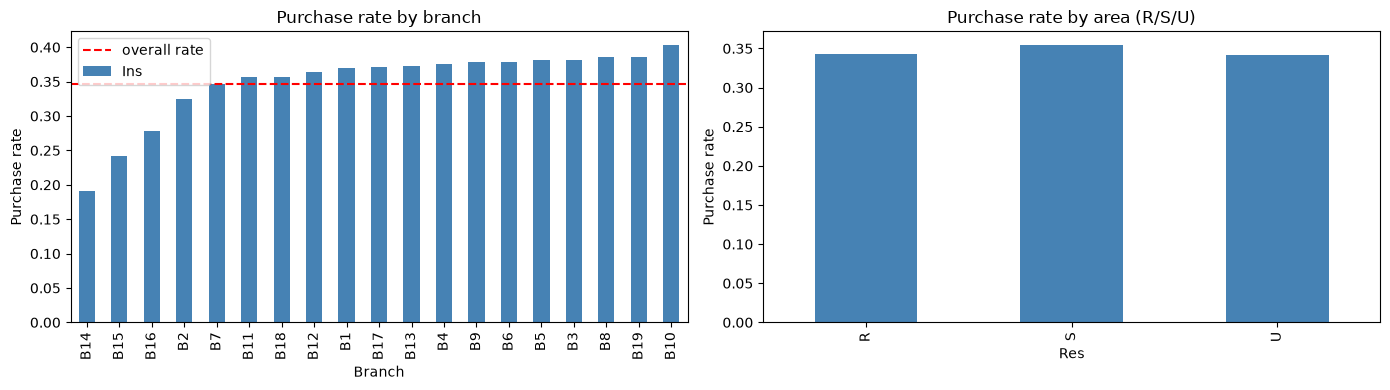

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
df.groupby("Branch")["Ins"].mean().sort_values().plot.bar(ax=axes[0], color="steelblue")
axes[0].axhline(df["Ins"].mean(), color="red", ls="--", label="overall rate")
axes[0].set_title("Purchase rate by branch"); axes[0].set_ylabel("Purchase rate"); axes[0].legend()
df.groupby("Res")["Ins"].mean().plot.bar(ax=axes[1], color="steelblue")
axes[1].set_title("Purchase rate by area (R/S/U)"); axes[1].set_ylabel("Purchase rate")
plt.tight_layout(); plt.show()

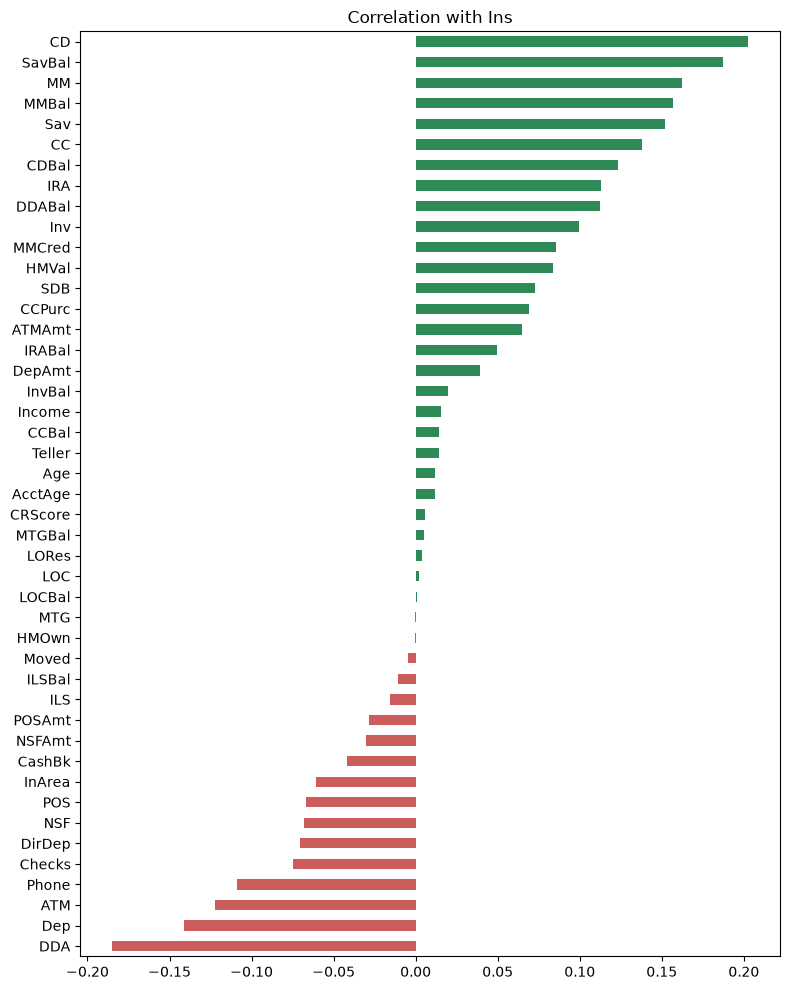

In [8]:
# Correlation of numeric inputs with the target
corr = df.drop(columns=["Branch", "Res"]).corr(numeric_only=True)["Ins"].drop("Ins").sort_values()
plt.figure(figsize=(8, 10))
corr.plot.barh(color=np.where(corr > 0, "seagreen", "indianred"))
plt.title("Correlation with Ins"); plt.tight_layout(); plt.show()

## 3. Data preparation

What was done and why:

* **Missing values.** 13 columns have missing values, up to about 20% of rows. The columns go missing in blocks (for example, Phone/POS/CC/Inv are all missing for the same 4,133 customers), and those customers buy at a lower rate (25% vs 36%). So dropping rows would waste data and bias the sample. Missing numbers are filled with the **median** (which outliers don't pull around), and a **missing-indicator flag** is added for each column so the models can use the "missing" signal itself.
* **Categorical variables.** `Branch` (19 levels) and `Res` (R/S/U) are **one-hot encoded**.
* **Skewed balances.** Balance and amount columns are highly right-skewed (e.g. CDBal max over $1M, median $0). For logistic regression and the neural network, a **signed log transform** (`sign(x)*log(1+|x|)`) followed by **standardization** is applied, because those models are sensitive to scale and outliers. Tree-based models (RF, GB) don't need this, so they get the raw imputed values.
* **Train/test split.** 70% train / 30% test, **stratified** on `Ins` so both sets keep the ~35% purchase rate. All preprocessing is fit only on the training data (inside a `Pipeline`) to avoid leakage.
* **Class balance.** A 35/65 split is only mildly imbalanced, so no resampling was done. Instead, the classification cut-off is examined in the threshold section.

In [9]:
X = df.drop(columns=["Ins"])
y = df["Ins"]

cat_cols = ["Branch", "Res"]
num_cols = [c for c in X.columns if c not in cat_cols]

# Skewed money/count columns that get a signed-log transform for the scale-sensitive models
skewed_cols = ["DDABal", "DepAmt", "NSFAmt", "SavBal", "ATMAmt", "POSAmt", "CDBal", "IRABal", "LOCBal",
               "ILSBal", "MMBal", "MTGBal", "CCBal", "InvBal", "Checks", "Dep", "Teller", "Phone", "POS",
               "AcctAge", "Income", "HMVal"]
other_num_cols = [c for c in num_cols if c not in skewed_cols]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=RANDOM_STATE)
print("Train:", X_train.shape, f"purchase rate {y_train.mean():.3f}")
print("Test: ", X_test.shape, f"purchase rate {y_test.mean():.3f}")

Train: (22584, 47) purchase rate 0.346
Test:  (9680, 47) purchase rate 0.346


In [10]:
def signed_log(x):
    return np.sign(x) * np.log1p(np.abs(x))

onehot = OneHotEncoder(handle_unknown="ignore", sparse_output=False)

# Preprocessing for tree models: impute + missing flags, one-hot categoricals
tree_prep = ColumnTransformer([
    ("num", SimpleImputer(strategy="median", add_indicator=True), num_cols),
    ("cat", onehot, cat_cols),
])

# Preprocessing for logistic regression / neural network: also log-transform skewed columns and scale
scaled_prep = ColumnTransformer([
    ("skewed", Pipeline([
        ("impute", SimpleImputer(strategy="median", add_indicator=True)),
        ("log", FunctionTransformer(signed_log, feature_names_out="one-to-one")),
        ("scale", StandardScaler()),
    ]), skewed_cols),
    ("other", Pipeline([
        ("impute", SimpleImputer(strategy="median", add_indicator=True)),
        ("scale", StandardScaler()),
    ]), other_num_cols),
    ("cat", onehot, cat_cols),
])

## 4. Build and tune the four models

Each model is a `Pipeline` (preprocessing + model). A small grid search with **5-fold stratified cross-validation on the training set** picks the settings, using ROC AUC as the score. The test set is not touched until evaluation.

In [11]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

models = {
    "Logistic Regression": (
        Pipeline([("prep", scaled_prep),
                  ("model", LogisticRegression(max_iter=2000, solver="liblinear"))]),
        {"model__C": [0.01, 0.1, 1.0], "model__penalty": ["l1", "l2"]},
    ),
    "Random Forest": (
        Pipeline([("prep", tree_prep),
                  ("model", RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=RANDOM_STATE))]),
        {"model__max_depth": [10, 20, None], "model__min_samples_leaf": [1, 5, 20]},
    ),
    "Gradient Boosting": (
        Pipeline([("prep", tree_prep),
                  ("model", HistGradientBoostingClassifier(max_iter=300, early_stopping=True,
                                                           random_state=RANDOM_STATE))]),
        {"model__learning_rate": [0.05, 0.1], "model__max_depth": [3, 6, None],
         "model__min_samples_leaf": [20, 50]},
    ),
    "Neural Network": (
        Pipeline([("prep", scaled_prep),
                  ("model", MLPClassifier(max_iter=500, early_stopping=True, random_state=RANDOM_STATE))]),
        {"model__hidden_layer_sizes": [(32,), (64, 32)], "model__alpha": [1e-3, 1e-2, 1e-1]},
    ),
}

fitted, cv_results = {}, []
for name, (pipe, grid) in models.items():
    search = GridSearchCV(pipe, grid, scoring="roc_auc", cv=cv, n_jobs=-1)
    search.fit(X_train, y_train)
    fitted[name] = search.best_estimator_
    cv_results.append({"Model": name, "CV AUC (mean)": search.best_score_,
                       "CV AUC (std)": search.cv_results_["std_test_score"][search.best_index_],
                       "Best parameters": search.best_params_})
    print(f"{name:20s} CV AUC = {search.best_score_:.4f}   {search.best_params_}")

pd.DataFrame(cv_results).round(4)

Logistic Regression  CV AUC = 0.7882   {'model__C': 0.1, 'model__penalty': 'l1'}


Random Forest        CV AUC = 0.7991   {'model__max_depth': 20, 'model__min_samples_leaf': 5}


Gradient Boosting    CV AUC = 0.8083   {'model__learning_rate': 0.05, 'model__max_depth': None, 'model__min_samples_leaf': 50}


Neural Network       CV AUC = 0.7848   {'model__alpha': 0.1, 'model__hidden_layer_sizes': (32,)}


,Model,CV AUC (mean),CV AUC (std),Best parameters
0,Logistic Regression,0.7882,0.0079,"{'model__C': 0.1, 'model__penalty': 'l1'}"
1,Random Forest,0.7991,0.0085,"{'model__max_depth': 20, 'model__min_samples_l..."
2,Gradient Boosting,0.8083,0.0079,"{'model__learning_rate': 0.05, 'model__max_dep..."
3,Neural Network,0.7848,0.0074,"{'model__alpha': 0.1, 'model__hidden_layer_siz..."


## 5. Evaluate on the held-out test set

Metrics at the default 0.5 probability cut-off:
* **ROC AUC**: how well the model ranks buyers above non-buyers (1.0 = perfect, 0.5 = random). This is the **primary metric** because it doesn't depend on the cut-off and matches the business goal of ranking customers for targeting.
* **Accuracy, Precision** (of those predicted to buy, what share did), **Recall** (of actual buyers, what share were found), **F1**.

In [12]:
probs = {name: m.predict_proba(X_test)[:, 1] for name, m in fitted.items()}

rows = []
for name, p in probs.items():
    pred = (p >= 0.5).astype(int)
    rows.append({"Model": name,
                 "ROC AUC": roc_auc_score(y_test, p),
                 "Accuracy": accuracy_score(y_test, pred),
                 "Precision": precision_score(y_test, pred),
                 "Recall": recall_score(y_test, pred),
                 "F1": f1_score(y_test, pred)})
results = pd.DataFrame(rows).sort_values("ROC AUC", ascending=False).reset_index(drop=True)
print(f"Baseline accuracy (always predict 'no'): {1 - y_test.mean():.4f}")
results.round(4)

Baseline accuracy (always predict 'no'): 0.6536


,Model,ROC AUC,Accuracy,Precision,Recall,F1
0,Gradient Boosting,0.8128,0.7555,0.6715,0.5756,0.6199
1,Random Forest,0.8084,0.7531,0.6768,0.5497,0.6066
2,Logistic Regression,0.7901,0.7385,0.6694,0.4843,0.5620
3,Neural Network,0.7889,0.7372,0.6435,0.5410,0.5878


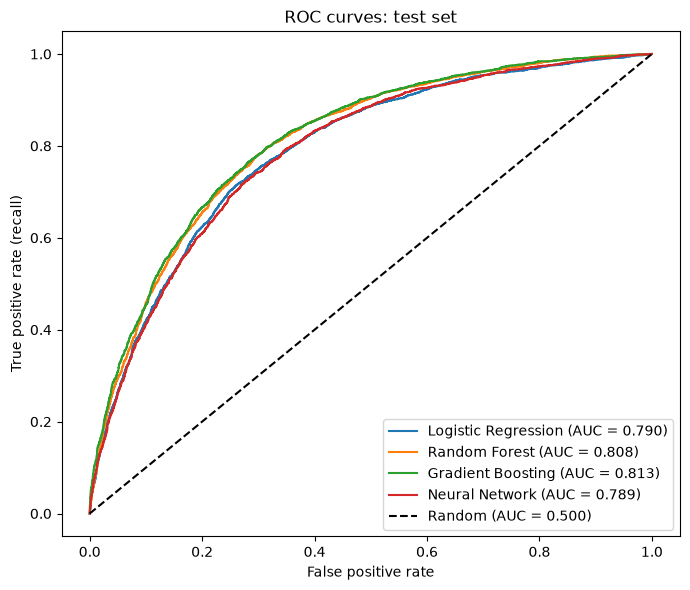

In [13]:
# ROC curves
plt.figure(figsize=(7, 6))
for name, p in probs.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, p):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random (AUC = 0.500)")
plt.xlabel("False positive rate"); plt.ylabel("True positive rate (recall)")
plt.title("ROC curves: test set"); plt.legend(loc="lower right"); plt.tight_layout(); plt.show()

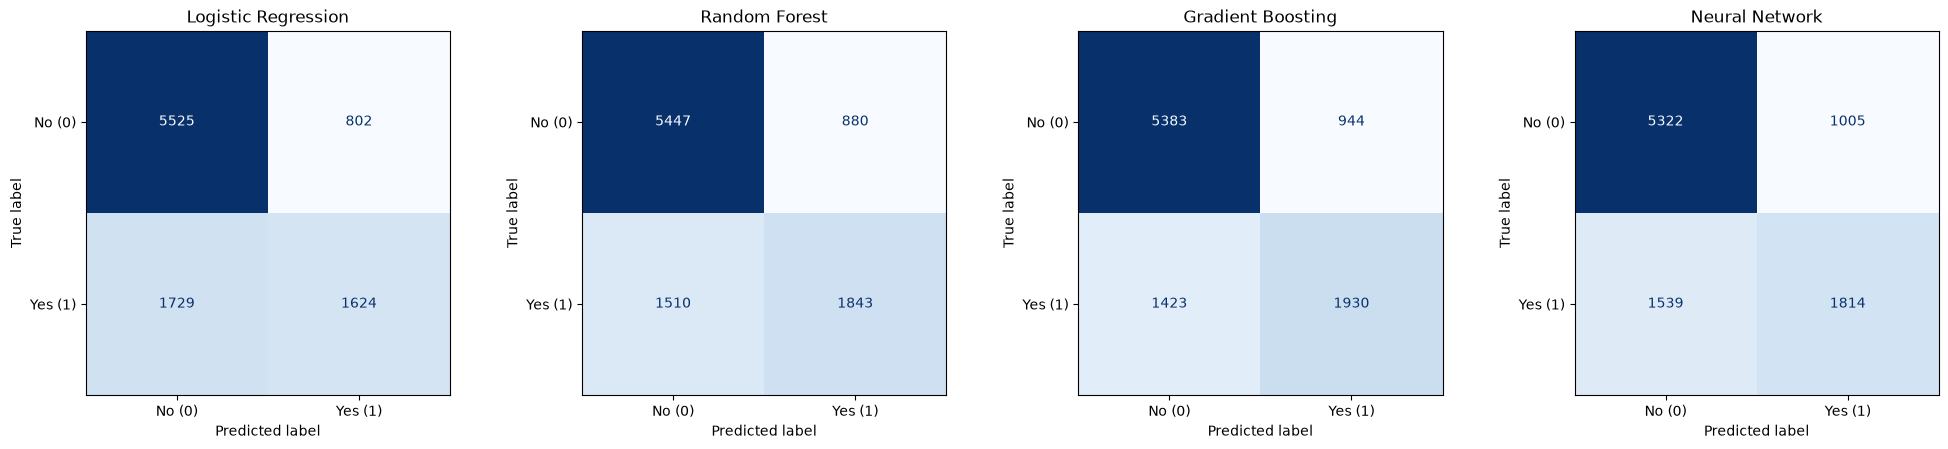

===== Logistic Regression =====
              precision    recall  f1-score   support

          No      0.762     0.873     0.814      6327
         Yes      0.669     0.484     0.562      3353

    accuracy                          0.739      9680
   macro avg      0.716     0.679     0.688      9680
weighted avg      0.730     0.739     0.726      9680

===== Random Forest =====
              precision    recall  f1-score   support

          No      0.783     0.861     0.820      6327
         Yes      0.677     0.550     0.607      3353

    accuracy                          0.753      9680
   macro avg      0.730     0.705     0.713      9680
weighted avg      0.746     0.753     0.746      9680

===== Gradient Boosting =====
              precision    recall  f1-score   support

          No      0.791     0.851     0.820      6327
         Yes      0.672     0.576     0.620      3353

    accuracy                          0.755      9680
   macro avg      0.731     0.713     0.

In [14]:
# Confusion matrices (0.5 cut-off)
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for ax, (name, p) in zip(axes, probs.items()):
    cm = confusion_matrix(y_test, (p >= 0.5).astype(int))
    ConfusionMatrixDisplay(cm, display_labels=["No (0)", "Yes (1)"]).plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(name)
plt.tight_layout(); plt.show()

for name, p in probs.items():
    print(f"===== {name} =====")
    print(classification_report(y_test, (p >= 0.5).astype(int), target_names=["No", "Yes"], digits=3))

### Cumulative gains and lift

For a marketing campaign, the practical question is: *if we only contact the top X% of customers ranked by the model, what share of all buyers do we reach?* Lift = (buyer rate in the targeted group) / (overall buyer rate).

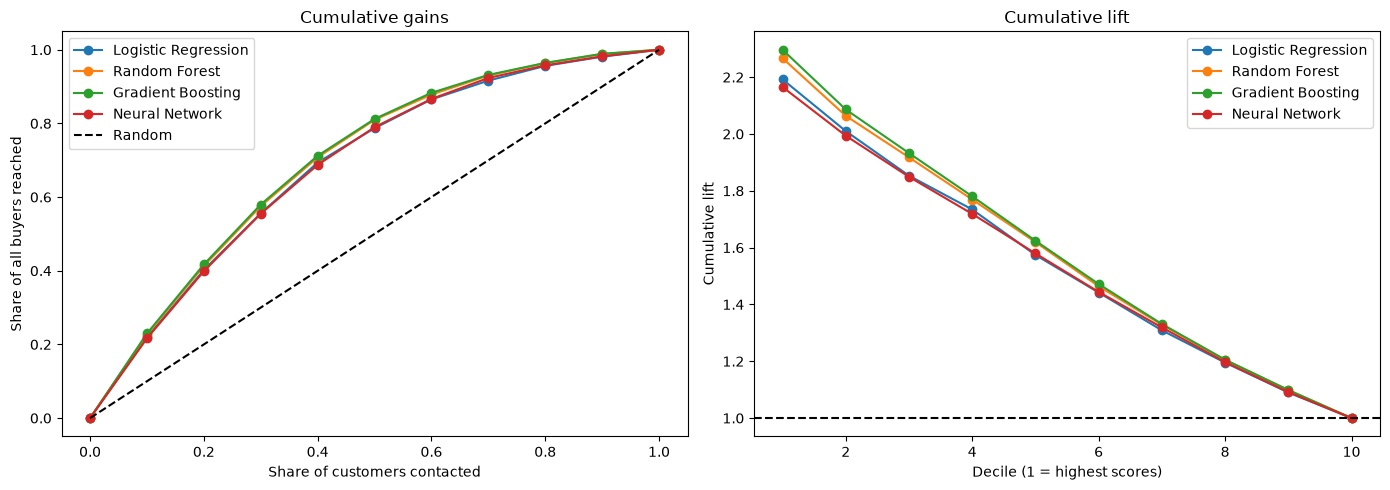

Gains table for the best model by AUC: Gradient Boosting


,customers,buyers,avg_score,response_rate,cum_pct_customers,cum_pct_buyers,cum_lift
decile,,,,,,,
1,968,770,0.777,0.795,0.1,0.230,2.296
2,968,629,0.644,0.650,0.2,0.417,2.086
3,968,545,0.545,0.563,0.3,0.580,1.933
4,968,444,0.444,0.459,0.4,0.712,1.780
5,968,335,0.345,0.346,0.5,0.812,1.624
6,968,238,0.256,0.246,0.6,0.883,1.472
7,968,163,0.176,0.168,0.7,0.932,1.331
8,968,109,0.124,0.113,0.8,0.964,1.205
9,968,83,0.088,0.086,0.9,0.989,1.099


In [15]:
def gains_table(y_true, p, n_bins=10):
    d = pd.DataFrame({"y": np.asarray(y_true), "p": p}).sort_values("p", ascending=False).reset_index(drop=True)
    d["decile"] = np.arange(len(d)) * n_bins // len(d) + 1
    g = d.groupby("decile").agg(customers=("y", "size"), buyers=("y", "sum"), avg_score=("p", "mean"))
    g["response_rate"] = g["buyers"] / g["customers"]
    g["cum_pct_customers"] = g["customers"].cumsum() / g["customers"].sum()
    g["cum_pct_buyers"] = g["buyers"].cumsum() / g["buyers"].sum()
    g["cum_lift"] = g["cum_pct_buyers"] / g["cum_pct_customers"]
    return g

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for name, p in probs.items():
    g = gains_table(y_test, p)
    axes[0].plot([0] + list(g["cum_pct_customers"]), [0] + list(g["cum_pct_buyers"]), marker="o", label=name)
    axes[1].plot(g.index, g["cum_lift"], marker="o", label=name)
axes[0].plot([0, 1], [0, 1], "k--", label="Random")
axes[0].set_xlabel("Share of customers contacted"); axes[0].set_ylabel("Share of all buyers reached")
axes[0].set_title("Cumulative gains"); axes[0].legend()
axes[1].axhline(1, color="k", ls="--")
axes[1].set_xlabel("Decile (1 = highest scores)"); axes[1].set_ylabel("Cumulative lift")
axes[1].set_title("Cumulative lift"); axes[1].legend()
plt.tight_layout(); plt.show()

best_name = results.loc[0, "Model"]
print(f"Gains table for the best model by AUC: {best_name}")
gains_table(y_test, probs[best_name]).round(3)

### Choosing a cut-off

0.5 is not necessarily the best cut-off for a campaign. Below, the threshold that maximizes F1 is shown for each model, which trades a bit of precision for many more buyers found. Management can choose a cut-off based on contact cost vs. revenue per sale.

In [16]:
rows = []
thresholds = np.arange(0.10, 0.91, 0.01)
for name, p in probs.items():
    f1s = [f1_score(y_test, (p >= t).astype(int)) for t in thresholds]
    t_best = thresholds[int(np.argmax(f1s))]
    pred = (p >= t_best).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    rows.append({"Model": name, "Best threshold": round(t_best, 2), "F1": max(f1s),
                 "Precision": precision_score(y_test, pred), "Recall": recall_score(y_test, pred),
                 "Accuracy": accuracy_score(y_test, pred), "TP": tp, "FP": fp, "FN": fn, "TN": tn})
pd.DataFrame(rows).round(4)

,Model,Best threshold,F1,Precision,Recall,Accuracy,TP,FP,FN,TN
0,Logistic Regression,0.32,0.6479,0.5678,0.7542,0.7160,2529,1925,824,4402
1,Random Forest,0.34,0.6656,0.5711,0.7975,0.7224,2674,2008,679,4319
2,Gradient Boosting,0.32,0.6659,0.5742,0.7924,0.7246,2657,1970,696,4357
3,Neural Network,0.31,0.6466,0.5475,0.7894,0.7010,2647,2188,706,4139


## 6. What drives purchase? (Variable importance)

* **Logistic regression coefficients.** Direction and strength of each variable (inputs are standardized, so the sizes can be compared).
* **Random forest importance.** How much each variable reduces impurity across the trees.
* **Permutation importance (gradient boosting).** How much test AUC drops when a variable's values are shuffled. This is the most reliable measure.

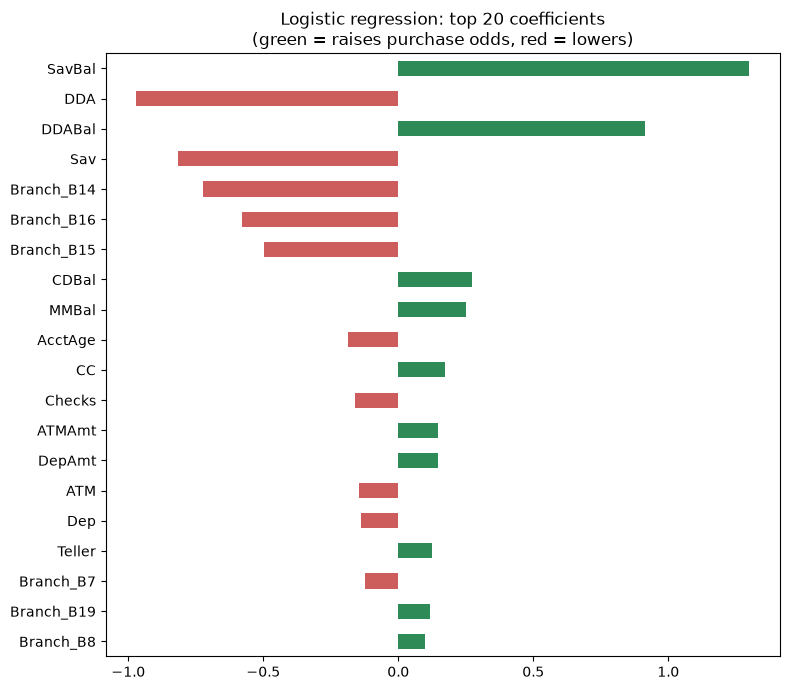

,coefficient,odds_ratio_per_1_SD
SavBal,1.300,3.670
DDA,-0.970,0.379
DDABal,0.913,2.492
Sav,-0.815,0.443
Branch_B14,-0.724,0.485
Branch_B16,-0.580,0.560
Branch_B15,-0.496,0.609
CDBal,0.274,1.315
MMBal,0.250,1.284
AcctAge,-0.188,0.829


In [17]:
# Logistic regression coefficients
lr = fitted["Logistic Regression"]
lr_names = lr.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(lr.named_steps["model"].coef_[0], index=lr_names)
coefs.index = coefs.index.str.replace(r"^(skewed|other|cat)__", "", regex=True)
top = coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(20)

plt.figure(figsize=(8, 7))
top[::-1].plot.barh(color=np.where(top[::-1] > 0, "seagreen", "indianred"))
plt.title("Logistic regression: top 20 coefficients\n(green = raises purchase odds, red = lowers)")
plt.tight_layout(); plt.show()

odds = pd.DataFrame({"coefficient": top, "odds_ratio_per_1_SD": np.exp(top)}).round(3)
odds

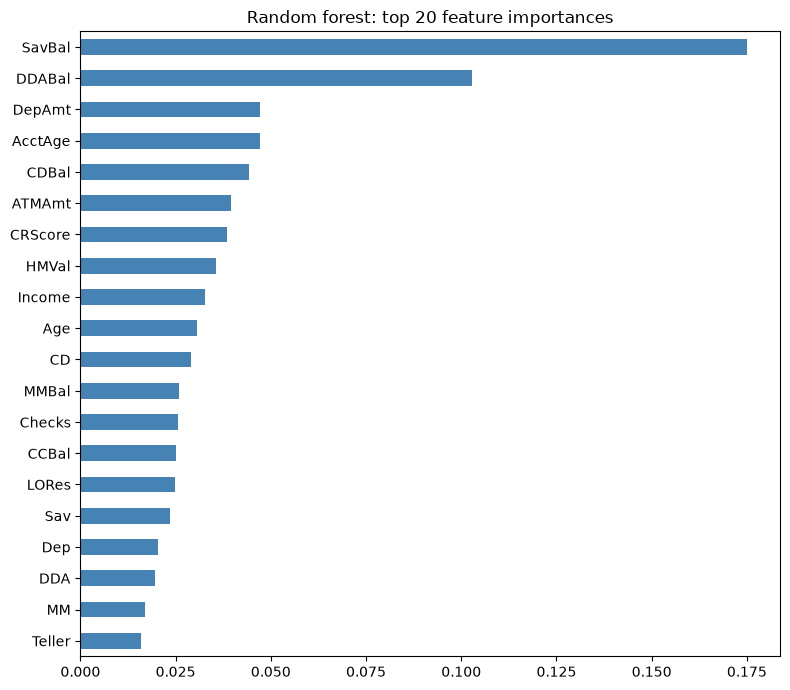

In [18]:
# Random forest impurity importance
rf = fitted["Random Forest"]
rf_names = rf.named_steps["prep"].get_feature_names_out()
rf_imp = pd.Series(rf.named_steps["model"].feature_importances_, index=rf_names)
rf_imp.index = rf_imp.index.str.replace(r"^(num|cat)__", "", regex=True)
rf_imp = rf_imp.sort_values(ascending=False).head(20)

plt.figure(figsize=(8, 7))
rf_imp[::-1].plot.barh(color="steelblue")
plt.title("Random forest: top 20 feature importances"); plt.tight_layout(); plt.show()

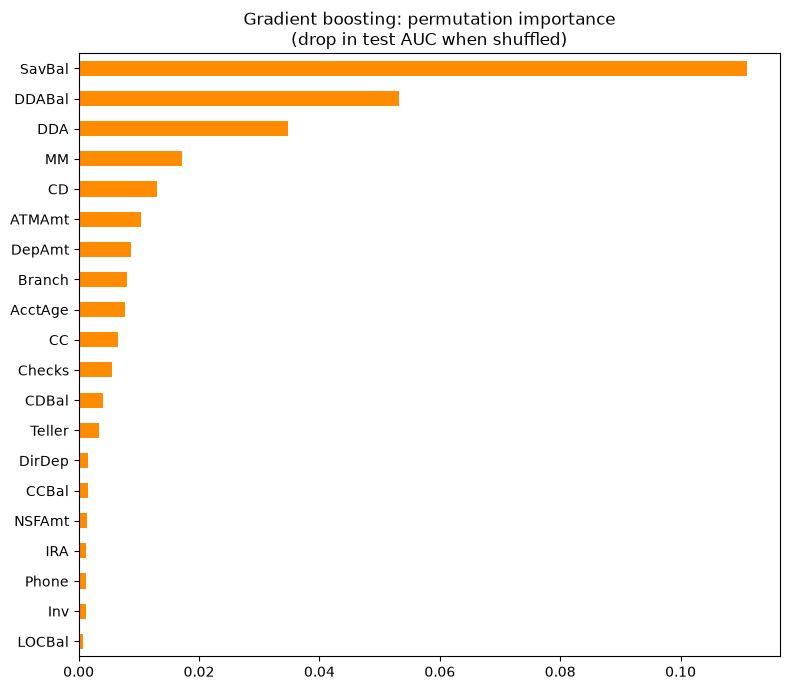

SavBal     0.1110
DDABal     0.0533
DDA        0.0348
MM         0.0172
CD         0.0129
ATMAmt     0.0103
DepAmt     0.0086
Branch     0.0080
AcctAge    0.0077
CC         0.0065
Checks     0.0056
CDBal      0.0041
Teller     0.0034
DirDep     0.0016
CCBal      0.0015
dtype: float64

In [19]:
# Permutation importance on the test set for gradient boosting (measured on the original columns)
perm = permutation_importance(fitted["Gradient Boosting"], X_test, y_test, scoring="roc_auc",
                              n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
perm_imp = pd.Series(perm.importances_mean, index=X_test.columns).sort_values(ascending=False)

plt.figure(figsize=(8, 7))
perm_imp.head(20)[::-1].plot.barh(color="darkorange")
plt.title("Gradient boosting: permutation importance\n(drop in test AUC when shuffled)")
plt.tight_layout(); plt.show()
perm_imp.head(15).round(4)

### Neural network: structure, training and results

A neural network has no simple coefficients or tree splits to read, so this subsection shows how it was built and trained, its own test results, and which variables it relies on (permutation importance, the same method used for gradient boosting).

Neural network (multi-layer perceptron) summary
  Layers (inputs -> hidden -> output): 82 -> 32 -> 1
  Hidden activation: relu   Output: logistic (probability of buying)
  L2 penalty (alpha): 0.1   Solver: adam
  Trainable weights: 2,689
  Training stopped after 26 epochs (early stopping on a 10% validation split)
  Best validation accuracy during training: 0.7402


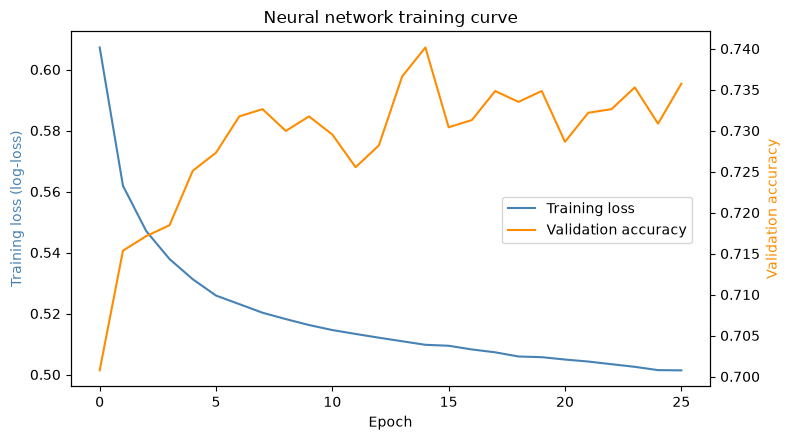

In [20]:
nn = fitted["Neural Network"]
mlp = nn.named_steps["model"]
n_inputs = nn.named_steps["prep"].transform(X_test.head(1)).shape[1]
layers = [n_inputs] + list(np.atleast_1d(mlp.hidden_layer_sizes)) + [1]

print("Neural network (multi-layer perceptron) summary")
print(f"  Layers (inputs -> hidden -> output): {' -> '.join(map(str, layers))}")
print(f"  Hidden activation: {mlp.activation}   Output: logistic (probability of buying)")
print(f"  L2 penalty (alpha): {mlp.alpha}   Solver: {mlp.solver}")
print(f"  Trainable weights: {sum(w.size for w in mlp.coefs_) + sum(b.size for b in mlp.intercepts_):,}")
print(f"  Training stopped after {mlp.n_iter_} epochs (early stopping on a 10% validation split)")
print(f"  Best validation accuracy during training: {mlp.best_validation_score_:.4f}")

fig, ax1 = plt.subplots(figsize=(8, 4.5))
ax1.plot(mlp.loss_curve_, color="steelblue", label="Training loss")
ax1.set_xlabel("Epoch"); ax1.set_ylabel("Training loss (log-loss)", color="steelblue")
ax2 = ax1.twinx()
ax2.plot(mlp.validation_scores_, color="darkorange", label="Validation accuracy")
ax2.set_ylabel("Validation accuracy", color="darkorange")
fig.legend(loc="center right", bbox_to_anchor=(0.88, 0.5))
plt.title("Neural network training curve"); fig.tight_layout(); plt.show()

Neural network test ROC AUC: 0.7889
Neural network test accuracy: 0.7372

              precision    recall  f1-score   support

          No      0.776     0.841     0.807      6327
         Yes      0.643     0.541     0.588      3353

    accuracy                          0.737      9680
   macro avg      0.710     0.691     0.697      9680
weighted avg      0.730     0.737     0.731      9680



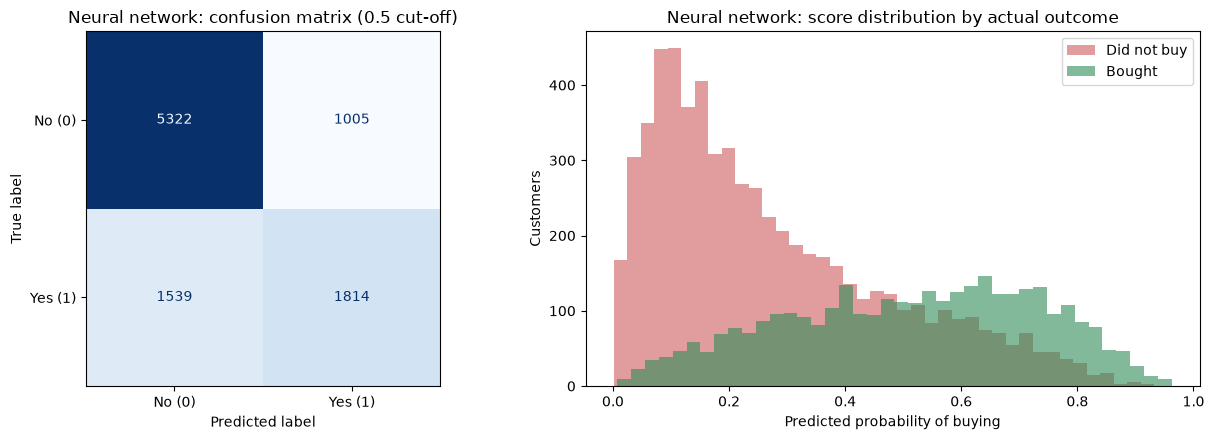

In [21]:
nn_p = probs["Neural Network"]
nn_pred = (nn_p >= 0.5).astype(int)
print(f"Neural network test ROC AUC: {roc_auc_score(y_test, nn_p):.4f}")
print(f"Neural network test accuracy: {accuracy_score(y_test, nn_pred):.4f}\n")
print(classification_report(y_test, nn_pred, target_names=["No", "Yes"], digits=3))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y_test, nn_pred), display_labels=["No (0)", "Yes (1)"]).plot(
    ax=axes[0], cmap="Blues", colorbar=False, values_format="d")
axes[0].set_title("Neural network: confusion matrix (0.5 cut-off)")
axes[1].hist(nn_p[y_test == 0], bins=40, alpha=0.6, label="Did not buy", color="indianred")
axes[1].hist(nn_p[y_test == 1], bins=40, alpha=0.6, label="Bought", color="seagreen")
axes[1].set_xlabel("Predicted probability of buying"); axes[1].set_ylabel("Customers")
axes[1].set_title("Neural network: score distribution by actual outcome"); axes[1].legend()
plt.tight_layout(); plt.show()

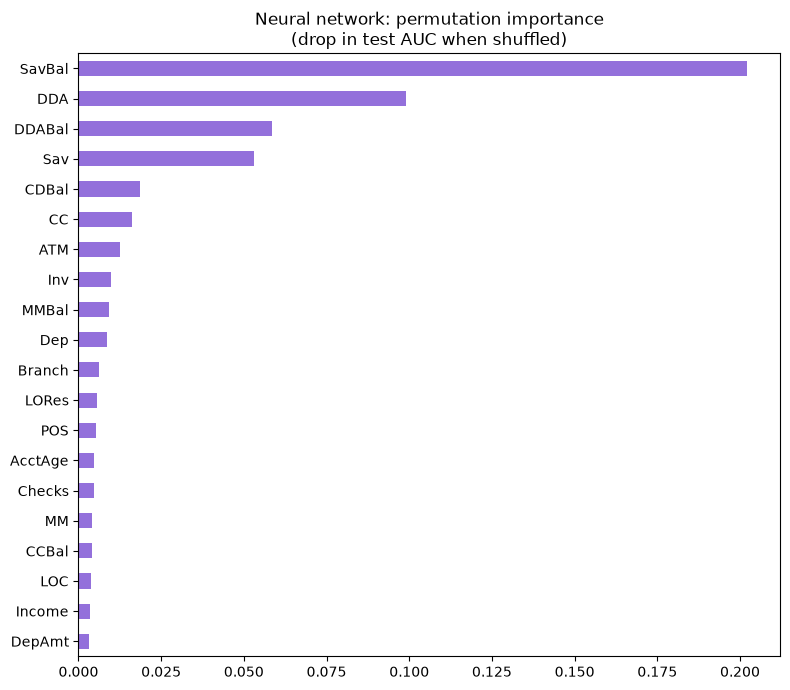

,Neural network,Gradient boosting
SavBal,0.2020,0.1110
DDA,0.0989,0.0348
DDABal,0.0586,0.0533
Sav,0.0530,0.0003
CDBal,0.0187,0.0041
CC,0.0162,0.0065
ATM,0.0126,0.0001
Inv,0.0100,0.0012
MMBal,0.0092,0.0003
Dep,0.0088,0.0006


In [22]:
nn_perm = permutation_importance(nn, X_test, y_test, scoring="roc_auc",
                                 n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
nn_imp = pd.Series(nn_perm.importances_mean, index=X_test.columns).sort_values(ascending=False)

plt.figure(figsize=(8, 7))
nn_imp.head(20)[::-1].plot.barh(color="mediumpurple")
plt.title("Neural network: permutation importance\n(drop in test AUC when shuffled)")
plt.tight_layout(); plt.show()

pd.DataFrame({"Neural network": nn_imp, "Gradient boosting": perm_imp}).sort_values(
    "Neural network", ascending=False).head(15).round(4)

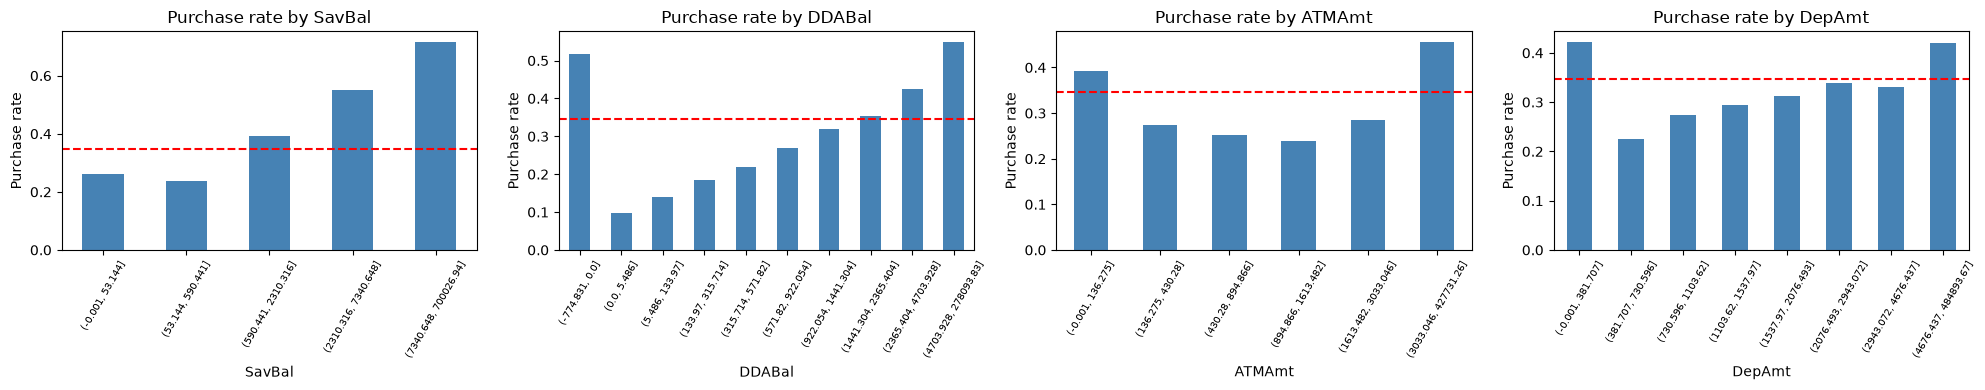

In [23]:
# Purchase rate by decile of the top continuous drivers, to show the direction of each effect
top_drivers = [c for c in perm_imp.index if df[c].nunique() > 10][:4]
fig, axes = plt.subplots(1, len(top_drivers), figsize=(5 * len(top_drivers), 4))
for ax, col in zip(np.atleast_1d(axes), top_drivers):
    bins = pd.qcut(df[col], q=10, duplicates="drop")
    df.groupby(bins, observed=True)["Ins"].mean().plot.bar(ax=ax, color="steelblue")
    ax.axhline(df["Ins"].mean(), color="red", ls="--")
    ax.set_title(f"Purchase rate by {col}"); ax.set_xlabel(col); ax.set_ylabel("Purchase rate")
    ax.tick_params(axis="x", labelrotation=60, labelsize=7)
plt.tight_layout(); plt.show()

## 7. Final model comparison

In [24]:
summary = pd.DataFrame(cv_results)[["Model", "CV AUC (mean)", "CV AUC (std)"]].merge(results, on="Model")
summary = summary.sort_values("ROC AUC", ascending=False).reset_index(drop=True)
top_decile_lift = {name: gains_table(y_test, p).loc[1, "cum_lift"] for name, p in probs.items()}
summary["Top-decile lift"] = summary["Model"].map(top_decile_lift)
summary.round(4)

,Model,CV AUC (mean),CV AUC (std),ROC AUC,Accuracy,Precision,Recall,F1,Top-decile lift
0,Gradient Boosting,0.8083,0.0079,0.8128,0.7555,0.6715,0.5756,0.6199,2.2965
1,Random Forest,0.7991,0.0085,0.8084,0.7531,0.6768,0.5497,0.6066,2.2666
2,Logistic Regression,0.7882,0.0079,0.7901,0.7385,0.6694,0.4843,0.5620,2.1921
3,Neural Network,0.7848,0.0074,0.7889,0.7372,0.6435,0.5410,0.5878,2.1652


In [25]:
print(f"Best model by test ROC AUC: {summary.loc[0, 'Model']} (AUC = {summary.loc[0, 'ROC AUC']:.4f})")

Best model by test ROC AUC: Gradient Boosting (AUC = 0.8128)


## 8. Recommendations analysis

This section turns the model findings into targeting rules management can act on:

1. Balance thresholds (where does the purchase rate clearly beat the average?)
2. Letting a shallow decision tree pick the cut points
3. A simple balance rule compared with the model's scores
4. A break-even cut-off calculator based on contact cost and profit per sale
5. Checking vs. savings customers, teller visits, ATM use, deposits, branches, and customers with missing data

Note: these are associations, not proof of cause. Any new campaign channel should be tested against a control group before rollout.

### 8.1 Purchase rate by savings and checking balance

In [26]:
overall_rate = df["Ins"].mean()
total_buyers = df["Ins"].sum()

def rate_by_band(col, edges):
    bands = pd.cut(df[col], edges, right=False)
    t = df.groupby(bands, observed=True)["Ins"].agg(customers="size", purchase_rate="mean")
    t["pct_of_customers"] = t["customers"] / len(df)
    t["lift_vs_avg"] = t["purchase_rate"] / overall_rate
    return t

sav_bands = rate_by_band("SavBal", [0, 1, 500, 1000, 2000, 3000, 5000, 7500, 10000, 20000, np.inf])
dda_bands = rate_by_band("DDABal", [-np.inf, 0, 500, 1000, 2000, 3000, 5000, 10000, np.inf])
print(f"Overall purchase rate: {overall_rate:.3f}\n")
print("Savings balance (SavBal):"); display(sav_bands.round(3))
print("Checking balance (DDABal):"); display(dda_bands.round(3))

Overall purchase rate: 0.346

Savings balance (SavBal):


,customers,purchase_rate,pct_of_customers,lift_vs_avg
SavBal,,,,
"[0.0, 1.0)",17737,0.275,0.550,0.794
"[1.0, 500.0)",4543,0.190,0.141,0.547
"[500.0, 1000.0)",1510,0.320,0.047,0.924
"[1000.0, 2000.0)",1637,0.420,0.051,1.212
"[2000.0, 3000.0)",1150,0.481,0.036,1.388
"[3000.0, 5000.0)",1446,0.541,0.045,1.563
"[5000.0, 7500.0)",1071,0.603,0.033,1.741
"[7500.0, 10000.0)",718,0.638,0.022,1.842
"[10000.0, 20000.0)",1255,0.711,0.039,2.052


Checking balance (DDABal):


,customers,purchase_rate,pct_of_customers,lift_vs_avg
DDABal,,,,
"[-inf, 0.0)",198,0.106,0.006,0.306
"[0.0, 500.0)",15147,0.315,0.469,0.909
"[500.0, 1000.0)",4634,0.268,0.144,0.773
"[1000.0, 2000.0)",4803,0.331,0.149,0.955
"[2000.0, 3000.0)",2329,0.402,0.072,1.162
"[3000.0, 5000.0)",2121,0.442,0.066,1.275
"[5000.0, 10000.0)",1771,0.517,0.055,1.493
"[10000.0, inf)",1261,0.607,0.039,1.754


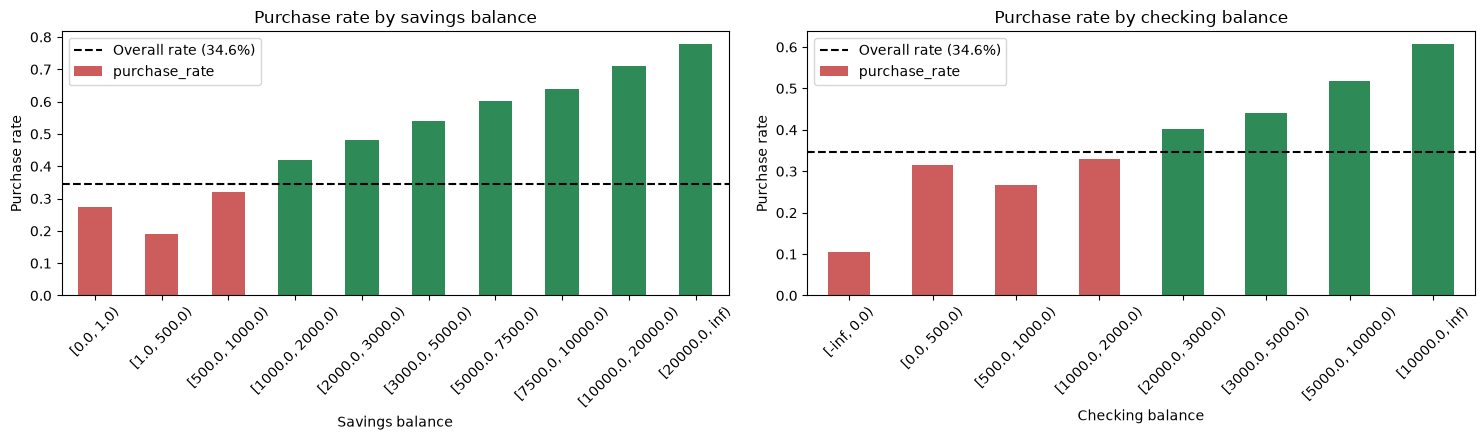

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, (t, title) in zip(axes, [(sav_bands, "Savings balance"), (dda_bands, "Checking balance")]):
    t["purchase_rate"].plot.bar(ax=ax, color=np.where(t["purchase_rate"] > overall_rate, "seagreen", "indianred"))
    ax.axhline(overall_rate, color="black", ls="--", label=f"Overall rate ({overall_rate:.1%})")
    ax.set_title(f"Purchase rate by {title.lower()}"); ax.set_xlabel(title); ax.set_ylabel("Purchase rate")
    ax.tick_params(axis="x", labelrotation=45); ax.legend()
plt.tight_layout(); plt.show()

### 8.2 Cumulative thresholds: "target everyone at or above $X"

For each candidate threshold: how many customers would be contacted, what share of them buy, and what share of **all** buyers the campaign would reach.

In [28]:
def threshold_table(col, thresholds):
    rows = []
    for x in thresholds:
        s = df[df[col] >= x]
        rows.append({f"{col} >= ": x, "pct_of_customers": len(s) / len(df), "purchase_rate": s["Ins"].mean(),
                     "lift_vs_avg": s["Ins"].mean() / overall_rate, "pct_of_all_buyers": s["Ins"].sum() / total_buyers})
    return pd.DataFrame(rows)

print("Savings thresholds:")
display(threshold_table("SavBal", [500, 1000, 1500, 2000, 3000, 4000, 5000, 8000, 10000, 20000]).round(3))
print("Checking thresholds:")
display(threshold_table("DDABal", [1000, 2000, 3000, 5000, 10000]).round(3))

Savings thresholds:


,SavBal >=,pct_of_customers,purchase_rate,lift_vs_avg,pct_of_all_buyers
0,500,0.309,0.544,1.571,0.486
1,1000,0.263,0.584,1.687,0.443
2,1500,0.235,0.608,1.756,0.412
3,2000,0.212,0.624,1.801,0.382
4,3000,0.176,0.653,1.884,0.332
5,4000,0.151,0.675,1.950,0.295
6,5000,0.131,0.690,1.993,0.262
7,8000,0.093,0.728,2.100,0.195
8,10000,0.076,0.744,2.148,0.163
9,20000,0.037,0.779,2.248,0.083


Checking thresholds:


,DDABal >=,pct_of_customers,purchase_rate,lift_vs_avg,pct_of_all_buyers
0,1000,0.381,0.419,1.209,0.460
1,2000,0.232,0.475,1.372,0.318
2,3000,0.160,0.508,1.467,0.234
3,5000,0.094,0.555,1.602,0.151
4,10000,0.039,0.607,1.754,0.069


### 8.3 Let a decision tree find the cut points

A shallow decision tree using only savings and checking balance picks the split points that best separate buyers from non-buyers. The leaves are printed as simple segments.

|--- SavBal <= 1532
|   |--- DDABal <= 0
|   |   |--- SavBal <= 0
|   |   |   |--- class: 0
|   |   |--- SavBal >  0
|   |   |   |--- class: 0
|   |--- DDABal >  0
|   |   |--- DDABal <= 2049
|   |   |   |--- class: 0
|   |   |--- DDABal >  2049
|   |   |   |--- class: 0
|--- SavBal >  1532
|   |--- SavBal <= 8336
|   |   |--- SavBal <= 3864
|   |   |   |--- class: 0
|   |   |--- SavBal >  3864
|   |   |   |--- class: 1
|   |--- SavBal >  8336
|   |   |--- SavBal <= 24618
|   |   |   |--- class: 1
|   |   |--- SavBal >  24618
|   |   |   |--- class: 1



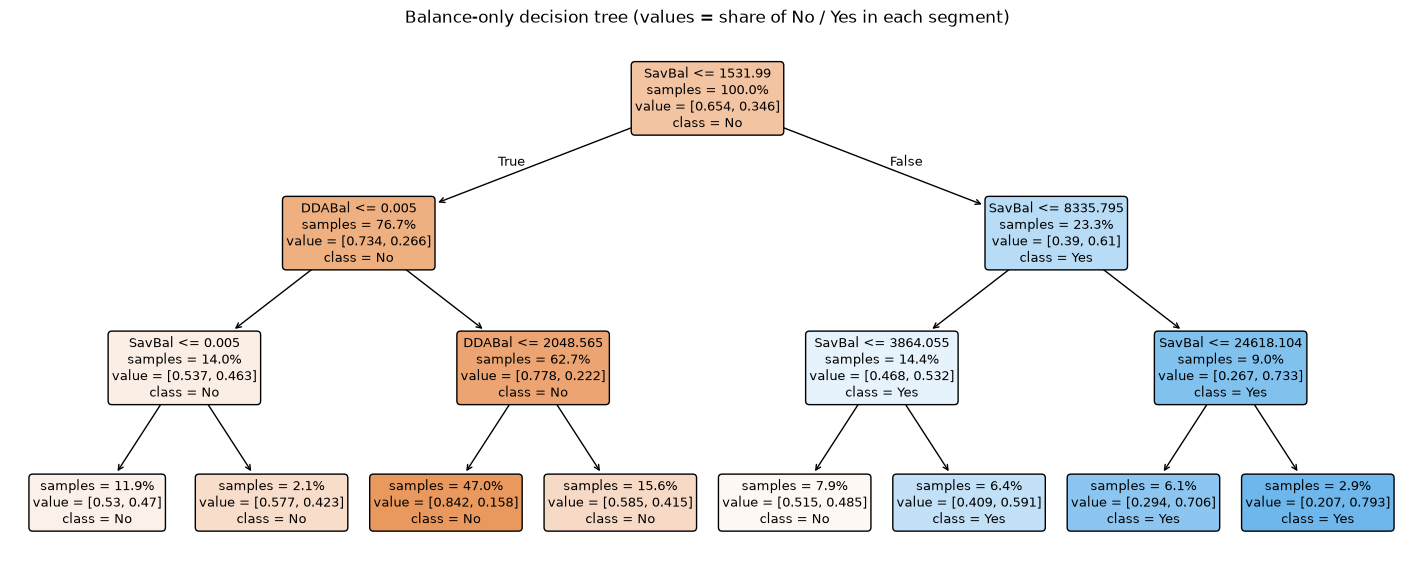

In [29]:
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree

bal_cols = ["SavBal", "DDABal"]
seg_tree = DecisionTreeClassifier(max_depth=3, min_samples_leaf=500, random_state=RANDOM_STATE)
seg_tree.fit(df[bal_cols], df["Ins"])
print(export_text(seg_tree, feature_names=bal_cols, decimals=0))

plt.figure(figsize=(18, 7))
plot_tree(seg_tree, feature_names=bal_cols, class_names=["No", "Yes"], filled=True, proportion=True,
          impurity=False, rounded=True, fontsize=9)
plt.title("Balance-only decision tree (values = share of No / Yes in each segment)")
plt.show()

In [30]:
# Segment summary: one row per leaf of the tree
leaf = seg_tree.apply(df[bal_cols])
segments = df.assign(segment=leaf).groupby("segment").agg(
    customers=("Ins", "size"), purchase_rate=("Ins", "mean"),
    SavBal_min=("SavBal", "min"), SavBal_max=("SavBal", "max"),
    DDABal_min=("DDABal", "min"), DDABal_max=("DDABal", "max"))
segments["pct_of_customers"] = segments["customers"] / len(df)
segments.sort_values("purchase_rate", ascending=False).round(3)

,customers,purchase_rate,SavBal_min,SavBal_max,DDABal_min,DDABal_max,pct_of_customers
segment,,,,,,,
14,922,0.793,24631.86,700026.94,0.00,155894.89,0.029
13,1978,0.706,8336.62,24604.35,-48.25,168723.80,0.061
11,2078,0.591,3864.68,8334.97,-19.12,252052.54,0.064
10,2554,0.485,1532.06,3863.43,-25.25,214068.86,0.079
3,3833,0.470,0.00,0.00,-351.40,0.00,0.119
4,679,0.423,0.01,1528.81,-774.83,0.00,0.021
7,5045,0.415,0.00,1528.04,2048.71,278093.83,0.156
6,15175,0.158,0.00,1531.92,0.01,2048.42,0.470


### 8.4 Simple balance rule vs. the model

Rule: **savings ≥ $3,000 OR checking ≥ $5,000**. On the test set, the rule is compared with the best model contacting the **same number** of customers (its highest scores).

In [31]:
def rule(X):
    return ((X["SavBal"] >= 3000) | (X["DDABal"] >= 5000)).astype(int)

best_p = probs[best_name]
rule_flag = rule(X_test)
n_contact = rule_flag.sum()
model_flag = np.zeros(len(X_test), dtype=int)
model_flag[np.argsort(-best_p)[:n_contact]] = 1

test_buyers = y_test.sum()
comparison = pd.DataFrame([
    {"Approach": "Balance rule", "customers_contacted": n_contact, "pct_contacted": n_contact / len(X_test),
     "purchase_rate": y_test[rule_flag == 1].mean(), "pct_of_buyers_reached": y_test[rule_flag == 1].sum() / test_buyers},
    {"Approach": f"{best_name} (top scores)", "customers_contacted": n_contact, "pct_contacted": n_contact / len(X_test),
     "purchase_rate": y_test[model_flag == 1].mean(), "pct_of_buyers_reached": y_test[model_flag == 1].sum() / test_buyers},
    {"Approach": "Random (no targeting)", "customers_contacted": n_contact, "pct_contacted": n_contact / len(X_test),
     "purchase_rate": y_test.mean(), "pct_of_buyers_reached": n_contact / len(X_test)},
])
comparison.round(3)

,Approach,customers_contacted,pct_contacted,purchase_rate,pct_of_buyers_reached
0,Balance rule,2403,0.248,0.603,0.432
1,Gradient Boosting (top scores),2403,0.248,0.701,0.503
2,Random (no targeting),2403,0.248,0.346,0.248


### 8.5 Break-even cut-off calculator

Contacting a customer pays off when *probability of buying × profit per sale > cost per contact*. So the break-even cut-off is **cost per contact ÷ profit per sale**.

The two numbers below are **placeholders**; change them to the bank's real figures and re-run. Results are for the test set (9,680 customers).

In [32]:
COST_PER_CONTACT = 50.0    # e.g. advisor call + mailer + staff time, in dollars (placeholder)
PROFIT_PER_SALE = 150.0    # profit from one annuity sale, in dollars (placeholder)

break_even = COST_PER_CONTACT / PROFIT_PER_SALE
print(f"Break-even probability cut-off: {break_even:.3f}\n")

def campaign(flag, label):
    flag = np.asarray(flag).astype(bool)
    contacted, buyers = flag.sum(), y_test[flag].sum()
    return {"Approach": label, "contacted": contacted, "buyers": buyers,
            "pct_of_buyers_reached": buyers / test_buyers,
            "profit": buyers * PROFIT_PER_SALE - contacted * COST_PER_CONTACT}

plans = pd.DataFrame([
    campaign(np.ones(len(X_test)), "Contact everyone"),
    campaign(rule_flag, "Balance rule (Sav >= 3k or DDA >= 5k)"),
    campaign(best_p >= break_even, f"{best_name}, score >= break-even"),
    campaign(best_p >= 0.5, f"{best_name}, score >= 0.5"),
])
plans.round(3)

Break-even probability cut-off: 0.333



,Approach,contacted,buyers,pct_of_buyers_reached,profit
0,Contact everyone,9680,3353,1.000,18950.0
1,Balance rule (Sav >= 3k or DDA >= 5k),2403,1448,0.432,97050.0
2,"Gradient Boosting, score >= break-even",4476,2606,0.777,167100.0
3,"Gradient Boosting, score >= 0.5",2874,1930,0.576,145800.0


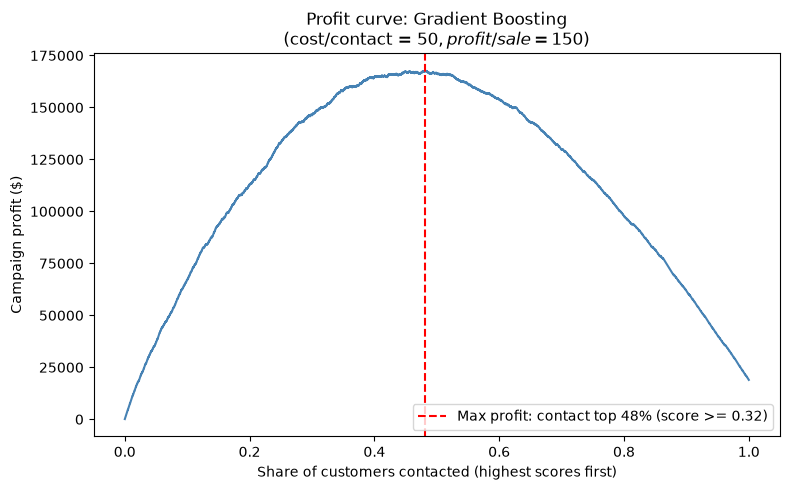

In [33]:
# Profit curve: expected campaign profit when contacting the top-k% of customers by model score
order = np.argsort(-best_p)
y_sorted = y_test.to_numpy()[order]
k = np.arange(1, len(y_sorted) + 1)
profit_curve = np.cumsum(y_sorted) * PROFIT_PER_SALE - k * COST_PER_CONTACT
best_k = int(np.argmax(profit_curve))

plt.figure(figsize=(8, 5))
plt.plot(k / len(k), profit_curve, color="steelblue")
plt.axvline((best_k + 1) / len(k), color="red", ls="--",
            label=f"Max profit: contact top {(best_k + 1) / len(k):.0%} (score >= {best_p[order][best_k]:.2f})")
plt.xlabel("Share of customers contacted (highest scores first)"); plt.ylabel("Campaign profit ($)")
plt.title(f"Profit curve: {best_name}\n(cost/contact = ${COST_PER_CONTACT:.0f}, profit/sale = ${PROFIT_PER_SALE:.0f})")
plt.legend(); plt.tight_layout(); plt.show()

### 8.6 Checking vs. savings customers

Owning a checking account on its own is associated with a *lower* purchase rate. Customers without checking tend to be savers and investors.

In [34]:
print("Purchase rate by checking (DDA) and savings (Sav) ownership:")
display(df.groupby(["DDA", "Sav"])["Ins"].agg(customers="size", purchase_rate="mean").round(3))

product_cols = ["Sav", "CD", "MM", "IRA", "Inv", "CC"]
mix = df.groupby("DDA")[product_cols].mean().T
mix.columns = ["No checking (DDA=0)", "Has checking (DDA=1)"]
print("Share holding each other product:")
mix.round(3)

Purchase rate by checking (DDA) and savings (Sav) ownership:


customers  purchase_rate
DDA Sav                          
0   0         3657          0.485
    1         2291          0.605
1   0        13543          0.223
    1        12773          0.391

Share holding each other product:


,No checking (DDA=0),Has checking (DDA=1)
Sav,0.385,0.485
CD,0.234,0.101
MM,0.296,0.074
IRA,0.107,0.041
Inv,0.074,0.020
CC,0.613,0.454


### 8.7 Channels: teller visits, ATM use and deposits

The data has **no ATM deposit field**. `ATM`/`ATMAmt` measure ATM **withdrawals**, and `Dep`/`DepAmt` count checking deposits without saying which channel was used. So the closest available measures are checked below.

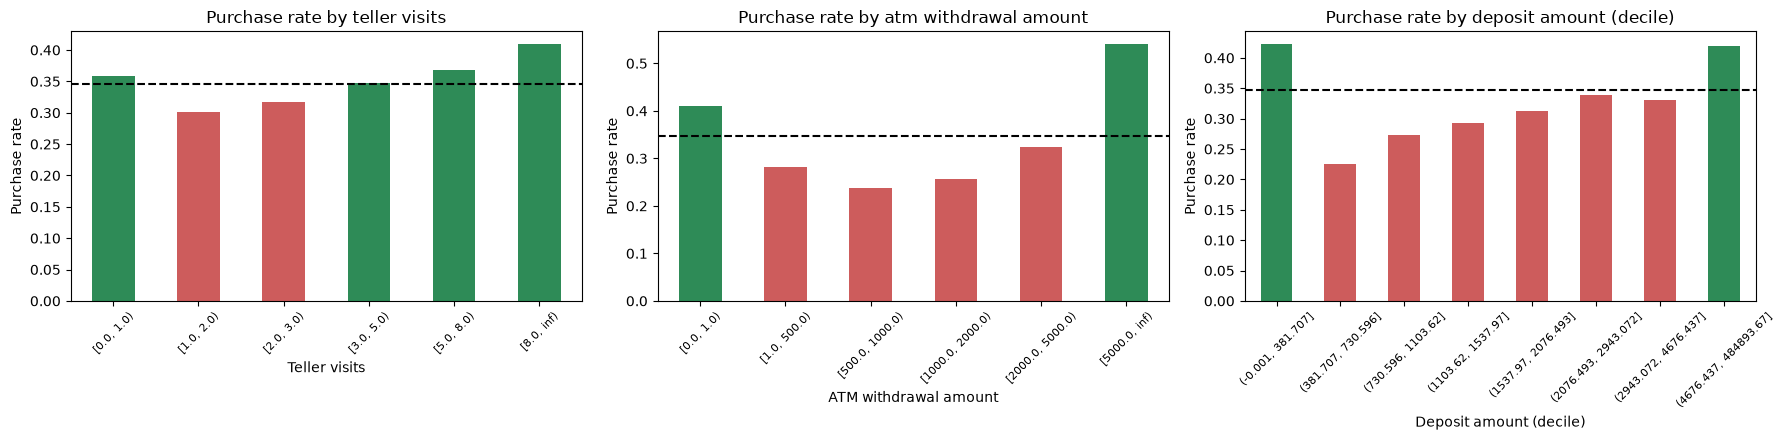

Teller visits


,customers,purchase_rate
Teller,,
"[0.0, 1.0)",17656,0.358
"[1.0, 2.0)",4918,0.302
"[2.0, 3.0)",3240,0.318
"[3.0, 5.0)",3564,0.347
"[5.0, 8.0)",2026,0.369
"[8.0, inf)",860,0.409


ATM withdrawal amount


,customers,purchase_rate
ATMAmt,,
"[0.0, 1.0)",13543,0.410
"[1.0, 500.0)",6388,0.282
"[500.0, 1000.0)",3240,0.237
"[1000.0, 2000.0)",3803,0.257
"[2000.0, 5000.0)",3667,0.325
"[5000.0, inf)",1623,0.540


Deposit amount (decile)


,customers,purchase_rate
DepAmt,,
"(-0.001, 381.707]",9679,0.423
"(381.707, 730.596]",3227,0.226
"(730.596, 1103.62]",3226,0.274
"(1103.62, 1537.97]",3226,0.294
"(1537.97, 2076.493]",3227,0.312
"(2076.493, 2943.072]",3226,0.339
"(2943.072, 4676.437]",3226,0.331
"(4676.437, 484893.67]",3227,0.420


Uses ATM (1) vs. not (0):


,customers,purchase_rate
ATM,,
0,12585,0.419
1,19679,0.300


In [35]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
channel_tables = {
    "Teller visits": df.groupby(pd.cut(df["Teller"], [0, 1, 2, 3, 5, 8, np.inf], right=False), observed=True)["Ins"].agg(["size", "mean"]),
    "ATM withdrawal amount": df.groupby(pd.cut(df["ATMAmt"], [0, 1, 500, 1000, 2000, 5000, np.inf], right=False), observed=True)["Ins"].agg(["size", "mean"]),
    "Deposit amount (decile)": df.groupby(pd.qcut(df["DepAmt"], 10, duplicates="drop"), observed=True)["Ins"].agg(["size", "mean"]),
}
for ax, (title, t) in zip(axes, channel_tables.items()):
    t["mean"].plot.bar(ax=ax, color=np.where(t["mean"] > overall_rate, "seagreen", "indianred"))
    ax.axhline(overall_rate, color="black", ls="--")
    ax.set_title(f"Purchase rate by {title.lower()}"); ax.set_ylabel("Purchase rate"); ax.set_xlabel(title)
    ax.tick_params(axis="x", labelrotation=45, labelsize=8)
plt.tight_layout(); plt.show()

for title, t in channel_tables.items():
    print(title); display(t.rename(columns={"size": "customers", "mean": "purchase_rate"}).round(3))
print("Uses ATM (1) vs. not (0):")
df.groupby("ATM")["Ins"].agg(customers="size", purchase_rate="mean").round(3)

In [36]:
# Using the model score at the point of contact: among customers who visit a teller or use an ATM,
# how concentrated are buyers in the top-scored 20%? (test set)
top20 = best_p >= np.quantile(best_p, 0.80)
rows = []
for label, mask in [("Visited a teller", X_test["Teller"].to_numpy() > 0),
                    ("Used an ATM", X_test["ATM"].to_numpy() == 1)]:
    rows.append({"Channel": label, "customers": mask.sum(),
                 "purchase_rate_all": y_test[mask].mean(),
                 "purchase_rate_top20_score": y_test[mask & top20].mean(),
                 "pct_of_channel_flagged": (mask & top20).sum() / mask.sum()})
pd.DataFrame(rows).round(3)

,Channel,customers,purchase_rate_all,purchase_rate_top20_score,pct_of_channel_flagged
0,Visited a teller,4335,0.335,0.737,0.178
1,Used an ATM,5861,0.290,0.734,0.163


### 8.8 Branch performance

In [37]:
branch = df.groupby("Branch").agg(customers=("Ins", "size"), purchase_rate=("Ins", "mean"),
                                  median_SavBal=("SavBal", "median"), median_DDABal=("DDABal", "median"),
                                  pct_has_savings=("Sav", "mean"))
# Rate expected from each branch's savings-balance mix alone (using the overall rate in each savings band)
sav_band = pd.cut(df["SavBal"], [0, 1, 500, 1000, 2000, 3000, 5000, 7500, 10000, 20000, np.inf], right=False)
band_rate = df.groupby(sav_band, observed=True)["Ins"].transform("mean")
branch["expected_from_savings_mix"] = band_rate.groupby(df["Branch"]).mean()
branch["gap_vs_overall"] = branch["purchase_rate"] - overall_rate
branch.sort_values("purchase_rate").round(3)

,customers,purchase_rate,median_SavBal,median_DDABal,pct_has_savings,expected_from_savings_mix,gap_vs_overall
Branch,,,,,,,
B14,1072,0.191,2.365,627.070,0.519,0.347,-0.155
B15,2235,0.243,0.000,776.900,0.503,0.349,-0.104
B16,1534,0.278,0.000,723.055,0.492,0.356,-0.069
B2,5345,0.325,0.000,474.430,0.273,0.314,-0.022
B7,1413,0.347,0.000,533.360,0.495,0.353,0.000
B11,247,0.356,0.330,536.460,0.518,0.355,0.010
B18,541,0.357,0.790,456.180,0.523,0.353,0.010
B12,549,0.364,3.490,582.440,0.525,0.336,0.018
B1,2819,0.370,0.000,547.530,0.498,0.353,0.024


### 8.9 Customers with missing data

In [38]:
missing_block = df["Phone"].isna()
print("Customers missing the Phone/POS/CC/Inv block:", missing_block.sum())
df.groupby(missing_block.rename("missing_block"))["Ins"].agg(customers="size", purchase_rate="mean").round(3)

Customers missing the Phone/POS/CC/Inv block: 4133


,customers,purchase_rate
missing_block,,
False,28131,0.360
True,4133,0.254
